# Tugas Akhir: Prediksi Cacat Produk Injection Molding

**Nama Tim:** KenjiYasmin  
**Anggota Kelompok:**
1. Kenji Ahmad Darelly (2405840)
2. Yasmin Tia Nizarini (2403165)

## Ringkasan Model & Artefak
- **Algoritma:** XGBoost (`versi_model`: 1.0.0)
- **Threshold Keputusan:** `0.23` (berdasarkan asumsi biaya FN = Rp500.000, FP = Rp25.000)
- **Performa Validasi (PR-AUC):** `0.6194` (Baseline LR: `0.4989`, Random Forest: `0.5913`)
- **Performa Data Uji (Test):** PR-AUC `0.6504` | Recall `0.8792` | Precision `0.2659`

In [11]:
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Buat struktur folder sesuai standar README_TIM.md
os.makedirs("data", exist_ok=True)
os.makedirs("src", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
os.makedirs("app/api", exist_ok=True)
os.makedirs("app/ui", exist_ok=True)
open("src/__init__.py", "a").close()

if "" not in sys.path:
    sys.path.insert(0, "")

RANDOM_STATE = 42

# Baca dataset
df_raw = pd.read_csv("raw.csv")
print(f"Ukuran data mentah: {df_raw.shape[0]:,} baris, {df_raw.shape[1]} kolom")
display(df_raw.head())

Ukuran data mentah: 25,350 baris, 12 kolom


,waktu_produksi,mesin,shift,bahan,suhu_leleh_C,suhu_cetakan_C,tekanan_injeksi_bar,kecepatan_injeksi_mm_s,waktu_pendinginan_s,waktu_siklus_s,kelembaban_bahan_pct,cacat
0,2026-03-01 00:12:45,IM-02,siang,PC,302.0,74.2,1053.0,68.6,15.1,27.5,0.088,0
1,2026-03-01 00:14:38,IM-01,pagi,P.P,219.6,40.1,1143.0,89.2,28.7,39.8,0.021,0
2,2026-03-01 00:19:00,IM-01,siang,ABS,230.6,67.7,945.0,89.2,15.2,29.2,0.046,0
3,2026-03-01 00:53:09,IM-01,malam,ABS,245.0,64.0,905.0,88.4,12.0,25.0,0.027,0
4,2026-03-01 01:07:19,IM-03,siang,PP,242.5,33.2,908.0,76.5,22.5,38.7,0.011,0


In [12]:
print("1. TIPE DATA & NILAI KOSONG")
print(df_raw.info())
print("\nJumlah nilai kosong per kolom:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])

print("\n2. BARIS DUPLIKAT")
print("Jumlah baris duplikat:", df_raw.duplicated().sum())

print("\n3. CEK NILAI KATEGORI (TEKS)")
for col in ["mesin", "shift", "bahan"]:
    print(f"\nKolom '{col}':")
    print(df_raw[col].value_counts(dropna=False))

print("\n4. STATISTIK NUMERIK (CEK NILAI MUSTAHIL)")
display(df_raw.describe().round(3))

print("\n5. PROPORSI TARGET (CACAT)")
rasio_cacat = df_raw["cacat"].mean()
print(f"Total produk cacat : {df_raw['cacat'].sum():,} dari {len(df_raw):,} ({rasio_cacat:.2%})")
print(f"Baseline tebak acak (PR-AUC): {rasio_cacat:.4f}")

1. TIPE DATA & NILAI KOSONG
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25350 entries, 0 to 25349
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   waktu_produksi          25350 non-null  object 
 1   mesin                   25350 non-null  object 
 2   shift                   25350 non-null  object 
 3   bahan                   25350 non-null  object 
 4   suhu_leleh_C            25350 non-null  float64
 5   suhu_cetakan_C          25350 non-null  float64
 6   tekanan_injeksi_bar     25350 non-null  float64
 7   kecepatan_injeksi_mm_s  25350 non-null  float64
 8   waktu_pendinginan_s     25093 non-null  float64
 9   waktu_siklus_s          25350 non-null  float64
 10  kelembaban_bahan_pct    24342 non-null  float64
 11  cacat                   25350 non-null  int64  
dtypes: float64(7), int64(1), object(4)
memory usage: 2.3+ MB
None

Jumlah nilai kosong per kolom:
waktu_pendinginan_s   

,suhu_leleh_C,suhu_cetakan_C,tekanan_injeksi_bar,kecepatan_injeksi_mm_s,waktu_pendinginan_s,waktu_siklus_s,kelembaban_bahan_pct,cacat
count,25350.000,25350.000,25350.000,25350.000,25093.000,25350.000,24342.000,25350.000
mean,253.682,56.133,896.200,79.867,18.022,31.901,0.055,0.078
std,44.986,20.395,126.415,14.991,3.986,4.791,0.057,0.268
min,194.900,8.000,0.000,25.600,6.000,-1.000,0.000,0.000
25%,229.900,39.900,825.000,69.800,15.300,29.000,0.015,0.000
50%,238.700,51.200,900.000,79.800,18.000,32.000,0.033,0.000
75%,254.000,67.000,973.000,90.000,20.700,35.000,0.076,0.000
max,615.200,113.700,1310.000,139.200,35.100,50.000,0.514,1.000



5. PROPORSI TARGET (CACAT)
Total produk cacat : 1,979 dari 25,350 (7.81%)
Baseline tebak acak (PR-AUC): 0.0781


In [13]:
df = df_raw.copy()

# 1. Hapus baris duplikat persis
jml_duplikat = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplikat dihapus: {jml_duplikat} baris -> sisa {len(df):,} baris")

# 2. Rapikan kolom teks (hapus spasi berlebih dan seragamkan huruf besar/kecil)
df["mesin"] = df["mesin"].astype(str).str.strip().str.upper()
df["shift"] = df["shift"].astype(str).str.strip().str.lower()
df["bahan"] = df["bahan"].astype(str).str.strip().str.upper()

# 3. Ubah nilai mustahil secara fisika menjadi NaN (JANGAN hapus barisnya)
# Contoh aturan fisika injection molding: suhu, tekanan, kecepatan, waktu siklus <= 0 atau kelembaban < 0
kondisi_mustahil = {
    "suhu_leleh_C": df["suhu_leleh_C"] <= 0,
    "suhu_cetakan_C": df["suhu_cetakan_C"] <= 0,
    "tekanan_injeksi_bar": df["tekanan_injeksi_bar"] <= 0,
    "kecepatan_injeksi_mm_s": df["kecepatan_injeksi_mm_s"] <= 0,
    "waktu_pendinginan_s": df["waktu_pendinginan_s"] <= 0,
    "waktu_siklus_s": df["waktu_siklus_s"] <= 0,
    "kelembaban_bahan_pct": df["kelembaban_bahan_pct"] < 0,
}

for col, cond in kondisi_mustahil.items():
    n_err = cond.sum()
    if n_err > 0:
        df.loc[cond, col] = np.nan
        print(f"Nilai mustahil pada '{col}' diubah ke NaN: {n_err} baris")

# 4. Urutkan data berdasarkan waktu_produksi (wajib untuk time-based split)
df["waktu_produksi"] = pd.to_datetime(df["waktu_produksi"])
df = df.sort_values("waktu_produksi").reset_index(drop=True)
print("Rentang waktu data:", df["waktu_produksi"].min(), "s/d", df["waktu_produksi"].max())

Duplikat dihapus: 350 baris -> sisa 25,000 baris
Nilai mustahil pada 'tekanan_injeksi_bar' diubah ke NaN: 125 baris
Nilai mustahil pada 'waktu_siklus_s' diubah ke NaN: 75 baris
Rentang waktu data: 2026-03-01 00:12:45 s/d 2026-06-28 23:45:48


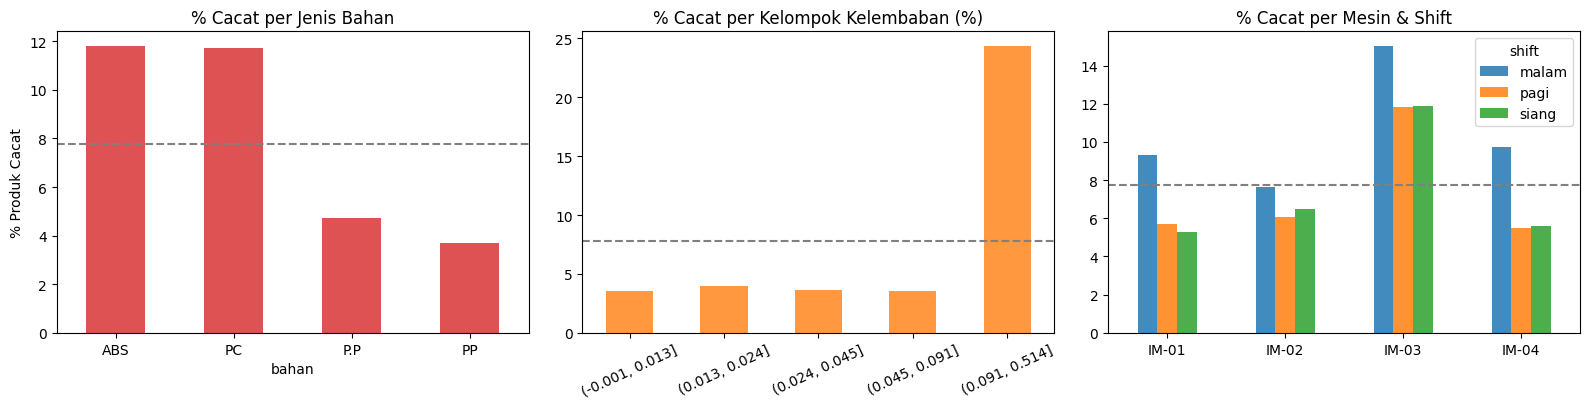

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
rata_cacat = df["cacat"].mean() * 100

# Grafik 1: % Cacat per Jenis Bahan
(df.groupby("bahan")["cacat"].mean() * 100).sort_values(ascending=False).plot.bar(
    ax=axes[0], color="tab:red", alpha=0.8
)
axes[0].axhline(rata_cacat, color="gray", linestyle="--", label="Rata-rata")
axes[0].set_title("% Cacat per Jenis Bahan")
axes[0].set_ylabel("% Produk Cacat")
axes[0].tick_params(axis="x", rotation=0)

# Grafik 2: % Cacat per Kelompok Kelembaban Bahan
lembab_bin = pd.qcut(df["kelembaban_bahan_pct"], q=5, duplicates="drop")
(df.groupby(lembab_bin, observed=True)["cacat"].mean() * 100).plot.bar(
    ax=axes[1], color="tab:orange", alpha=0.8
)
axes[1].axhline(rata_cacat, color="gray", linestyle="--")
axes[1].set_title("% Cacat per Kelompok Kelembaban (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)

# Grafik 3: % Cacat per Mesin & Shift
pivot_ms = df.pivot_table(index="mesin", columns="shift", values="cacat", aggfunc="mean") * 100
pivot_ms.plot.bar(ax=axes[2], alpha=0.85)
axes[2].axhline(rata_cacat, color="gray", linestyle="--")
axes[2].set_title("% Cacat per Mesin & Shift")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("eda_temuan_utama.png", dpi=150)
plt.show()

In [15]:
%%writefile src/features.py
"""Fitur rekayasa proses injection molding. Dipakai bersama saat training dan prediksi."""
import numpy as np
import pandas as pd

def tambah_fitur(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    # 1. Selisih suhu leleh plastik dengan suhu cetakan
    df["delta_suhu_C"] = df["suhu_leleh_C"] - df["suhu_cetakan_C"]

    # 2. Rasio waktu pendinginan terhadap total waktu siklus
    df["rasio_pendinginan"] = df["waktu_pendinginan_s"] / df["waktu_siklus_s"].replace(0, np.nan)

    # 3. Indikator energi/laju pengisian cetakan (tekanan x kecepatan injeksi)
    df["laju_energi_injeksi"] = df["tekanan_injeksi_bar"] * df["kecepatan_injeksi_mm_s"]

    # 4. Indikator risiko kelembaban terhadap suhu leleh tinggi
    df["indeks_uap"] = df["kelembaban_bahan_pct"] * df["suhu_leleh_C"]
    return df

Overwriting src/features.py


In [16]:
import importlib
import src.features
importlib.reload(src.features)
from src.features import tambah_fitur

uji = tambah_fitur(df.head(3))
print("Kolom baru berhasil dibuat:", [c for c in uji.columns if c not in df.columns])

Kolom baru berhasil dibuat: ['delta_suhu_C', 'rasio_pendinginan', 'laju_energi_injeksi', 'indeks_uap']


In [17]:
TARGET = "cacat"
FITUR_INPUT = [
    "mesin",
    "shift",
    "bahan",
    "suhu_leleh_C",
    "suhu_cetakan_C",
    "tekanan_injeksi_bar",
    "kecepatan_injeksi_mm_s",
    "waktu_pendinginan_s",
    "waktu_siklus_s",
    "kelembaban_bahan_pct",
]

n_total = len(df)
idx_train = int(0.60 * n_total)
idx_val = int(0.80 * n_total)

train_df = df.iloc[:idx_train]
val_df = df.iloc[idx_train:idx_val]
test_df = df.iloc[idx_val:]

X_train, y_train = train_df[FITUR_INPUT], train_df[TARGET]
X_val, y_val = val_df[FITUR_INPUT], val_df[TARGET]
X_test, y_test = test_df[FITUR_INPUT], test_df[TARGET]

print(f"Train : {len(X_train):,} baris | rasio cacat = {y_train.mean():.2%}")
print(f"Val   : {len(X_val):,} baris | rasio cacat = {y_val.mean():.2%}")
print(f"Test  : {len(X_test):,} baris | rasio cacat = {y_test.mean():.2%} (DIKUNCI sampai akhir)")

Train : 15,000 baris | rasio cacat = 7.68%
Val   : 5,000 baris | rasio cacat = 7.48%
Test  : 5,000 baris | rasio cacat = 8.28% (DIKUNCI sampai akhir)


In [18]:
import joblib, sklearn, xgboost
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, recall_score, precision_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

KOLOM_ANGKA = [
    "suhu_leleh_C", "suhu_cetakan_C", "tekanan_injeksi_bar",
    "kecepatan_injeksi_mm_s", "waktu_pendinginan_s", "waktu_siklus_s",
    "kelembaban_bahan_pct", "delta_suhu_C", "rasio_pendinginan",
    "laju_energi_injeksi", "indeks_uap"
]
KOLOM_KATEGORI = ["mesin", "shift", "bahan"]

def buat_pipeline(model, scale_num=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_num:
        num_steps.append(("scaler", StandardScaler()))
    preprocess = ColumnTransformer([
        ("angka", Pipeline(num_steps), KOLOM_ANGKA),
        ("kategori", OneHotEncoder(handle_unknown="ignore"), KOLOM_KATEGORI),
    ])
    return Pipeline([
        ("fitur", FunctionTransformer(tambah_fitur)),
        ("preprocess", preprocess),
        ("model", model),
    ])

# 1. Baseline: Logistic Regression sederhana
baseline_lr = buat_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE), scale_num=True)
baseline_lr.fit(X_train, y_train)
proba_lr = baseline_lr.predict_proba(X_val)[:, 1]

# 2. Model Pohon 1: Random Forest
rf = buat_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))
rf.fit(X_train, y_train)
proba_rf = rf.predict_proba(X_val)[:, 1]

# 3. Model Pohon 2: XGBoost
spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb = buat_pipeline(XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    scale_pos_weight=spw, random_state=RANDOM_STATE, n_jobs=-1
))
xgb.fit(X_train, y_train)
proba_xgb = xgb.predict_proba(X_val)[:, 1]

print(f"PR-AUC Validation · Dummy Acak          : {y_val.mean():.4f}")
print(f"PR-AUC Validation · Baseline (LogReg)   : {average_precision_score(y_val, proba_lr):.4f}")
print(f"PR-AUC Validation · Random Forest       : {average_precision_score(y_val, proba_rf):.4f}")
print(f"PR-AUC Validation · XGBoost             : {average_precision_score(y_val, proba_xgb):.4f}")

# Pilih model terbaik otomatis berdasarkan PR-AUC validation
kandidat_model = {
    "Baseline_LogisticRegression": (baseline_lr, proba_lr),
    "RandomForest": (rf, proba_rf),
    "XGBoost": (xgb, proba_xgb),
}
nama_terbaik = max(kandidat_model, key=lambda k: average_precision_score(y_val, kandidat_model[k][1]))
model_final, proba_val_final = kandidat_model[nama_terbaik]
pr_auc_val_final = average_precision_score(y_val, proba_val_final)
print(f"\nModel terpilih untuk final: {nama_terbaik} (PR-AUC Val = {pr_auc_val_final:.4f})")

# 4. Optimasi Threshold berdasarkan Biaya (sesuaikan jika angka FN/FP di brief berbeda)
BIAYA_FN = 500_000   # Contoh: biaya produk cacat lolos QC / keluhan pelanggan
BIAYA_FP = 25_000    # Contoh: biaya inspeksi ulang / henti sementara mesin

def hitung_biaya(y_true, proba, thr):
    tn, fp, fn, tp = confusion_matrix(y_true, proba >= thr).ravel()
    return fn * BIAYA_FN + fp * BIAYA_FP

kandidat_thr = np.round(np.arange(0.05, 0.96, 0.01), 2)
daftar_biaya = [hitung_biaya(y_val, proba_val_final, t) for t in kandidat_thr]
threshold_terbaik = float(kandidat_thr[np.argmin(daftar_biaya)])
print(f"Threshold terbaik (Val): {threshold_terbaik:.2f} | Total biaya: Rp {min(daftar_biaya):,.0f}")

# 5. BUKA TEST SET (SATU KALI SAJA DI AKHIR)
proba_test = model_final.predict_proba(X_test)[:, 1]
pr_auc_test = average_precision_score(y_test, proba_test)
recall_test = recall_score(y_test, proba_test >= threshold_terbaik)
precision_test = precision_score(y_test, proba_test >= threshold_terbaik)
tn, fp, fn, tp = confusion_matrix(y_test, proba_test >= threshold_terbaik).ravel()

print("\n=== HASIL AKHIR PADA TEST SET ===")
print(f"PR-AUC Test    : {pr_auc_test:.4f}")
print(f"Recall Test    : {recall_test:.2%} ({tp} dari {tp + fn} produk cacat tertangkap)")
print(f"Precision Test : {precision_test:.2%} (alarm palsu: {fp} dari {tn + fp} produk baik)")
print(f"Total Biaya    : Rp {hitung_biaya(y_test, proba_test, threshold_terbaik):,.0f}")

# 6. Simpan artifacts/model.joblib dan artifacts/metadata.json
joblib.dump(model_final, "artifacts/model.joblib")
metadata = {
    "versi_model": "1.0.0",
    "algoritma": nama_terbaik,
    "dibuat": time.strftime("%Y-%m-%d"),
    "fitur_input": FITUR_INPUT,
    "target": TARGET,
    "threshold": threshold_terbaik,
    "metrik_validasi": {
        "pr_auc_baseline_lr": round(float(average_precision_score(y_val, proba_lr)), 4),
        "pr_auc_rf": round(float(average_precision_score(y_val, proba_rf)), 4),
        "pr_auc_xgb": round(float(average_precision_score(y_val, proba_xgb)), 4),
    },
    "metrik_test": {
        "pr_auc": round(float(pr_auc_test), 4),
        "recall": round(float(recall_test), 4),
        "precision": round(float(precision_test), 4),
    },
    "asumsi_biaya": {"FN": BIAYA_FN, "FP": BIAYA_FP},
    "versi_library": {
        "python": sys.version.split()[0],
        "sklearn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "pandas": pd.__version__,
    },
}
with open("artifacts/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\nBerhasil menyimpan artifacts/model.joblib dan artifacts/metadata.json")

PR-AUC Validation · Dummy Acak          : 0.0748
PR-AUC Validation · Baseline (LogReg)   : 0.4989
PR-AUC Validation · Random Forest       : 0.5913
PR-AUC Validation · XGBoost             : 0.6194

Model terpilih untuk final: XGBoost (PR-AUC Val = 0.6194)
Threshold terbaik (Val): 0.23 | Total biaya: Rp 48,625,000

=== HASIL AKHIR PADA TEST SET ===
PR-AUC Test    : 0.6504
Recall Test    : 87.92% (364 dari 414 produk cacat tertangkap)
Precision Test : 26.59% (alarm palsu: 1005 dari 4586 produk baik)
Total Biaya    : Rp 50,125,000

Berhasil menyimpan artifacts/model.joblib dan artifacts/metadata.json
